# Этап 1. EDA

Из сырой выгрузки `data/raw/epl_odds_raw.csv` (этап 0) делаем рабочий датасет `data/transformed/epl_odds_2026-09-12_19.csv`:
- убираем служебные столбцы;
- переименовываем поля;
- приводим время к одному виду;
- убираем ошибочные цены;
- расшифровываем коды;
- добавляем производные поля;
- округляем.

Все время в данных - **UTC**

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Шаг 1. Загружаем выгрузку

In [46]:
raw = pd.read_csv("../data/raw/epl_odds_raw.csv")
print(raw.shape)
raw.head()

(71003, 13)


,fixtureId,startTime,participant1Name,participant2Name,bookmaker,marketId,outcomeId,playerId,createdAt,price,limit,active,exchangeMeta
0,id1000001772221252,2026-09-12T14:00:00.000Z,Aston Villa,Nottingham Forest,pinnacle,101,101,0,2026-08-30T19:48:20.892Z,1.781,320.0,True,NaN
1,id1000001772221252,2026-09-12T14:00:00.000Z,Aston Villa,Nottingham Forest,pinnacle,101,101,0,2026-08-30T19:48:26.392Z,1.806,310.0,True,NaN
2,id1000001772221252,2026-09-12T14:00:00.000Z,Aston Villa,Nottingham Forest,pinnacle,101,101,0,2026-08-30T19:48:46.525Z,1.813,307.0,True,NaN
3,id1000001772221252,2026-09-12T14:00:00.000Z,Aston Villa,Nottingham Forest,pinnacle,101,101,0,2026-08-30T19:48:46.829Z,1.909,275.0,True,NaN
4,id1000001772221252,2026-09-12T14:00:00.000Z,Aston Villa,Nottingham Forest,pinnacle,101,101,0,2026-08-30T20:46:01.164Z,1.934,267.0,True,NaN


In [47]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 71003 entries, 0 to 71002
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   fixtureId         71003 non-null  str    
 1   startTime         71003 non-null  str    
 2   participant1Name  71003 non-null  str    
 3   participant2Name  71003 non-null  str    
 4   bookmaker         71003 non-null  str    
 5   marketId          71003 non-null  int64  
 6   outcomeId         71003 non-null  int64  
 7   playerId          71003 non-null  int64  
 8   createdAt         71003 non-null  str    
 9   price             71003 non-null  float64
 10  limit             25743 non-null  float64
 11  active            71003 non-null  bool   
 12  exchangeMeta      0 non-null      float64
dtypes: bool(1), float64(3), int64(3), str(6)
memory usage: 6.6 MB


## Шаг 2. Служебные столбцы

`playerId` нужен только для ставок на игроков, `exchangeMeta` — что-то для бирж ставок. Проверяем, что в наших данных в них ничего нет.

In [48]:
print("Значения playerId:", raw["playerId"].unique())
print("exchangeMeta пустой везде:", raw["exchangeMeta"].isna().all())

Значения playerId: [0]
exchangeMeta пустой везде: True


In [49]:
df = raw.drop(columns=["playerId", "exchangeMeta"])

## Шаг 4. Переименовываем поля

Переименовываем поля, неочевидные называем по смыслу. `limit` есть только у Pinnacle, поэтому `pinnacle_limit`.

In [50]:
df = df.rename(columns={
    "fixtureId": "fixture_id",
    "startTime": "kickoff",
    "participant1Name": "home",
    "participant2Name": "away",
    "marketId": "market_id",
    "outcomeId": "outcome_id",
    "createdAt": "timestamp",
    "limit": "pinnacle_limit",
    "active": "bool_isActive",
})
df.columns.tolist()

['fixture_id',
 'kickoff',
 'home',
 'away',
 'bookmaker',
 'market_id',
 'outcome_id',
 'timestamp',
 'price',
 'pinnacle_limit',
 'bool_isActive']

## Шаг 5. Время

время записано строкой в UTC (`2026-09-12T14:00:00.000Z`). Переводим в datetime и убираем пометку часового пояса: все время в датасете и так UTC.

In [51]:
df["kickoff"] = pd.to_datetime(df["kickoff"]).dt.tz_localize(None)
df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.tz_localize(None)
df[["kickoff", "timestamp"]].head()

,kickoff,timestamp
0,2026-09-12 14:00:00,2026-08-30 19:48:20.892
1,2026-09-12 14:00:00,2026-08-30 19:48:26.392
2,2026-09-12 14:00:00,2026-08-30 19:48:46.525
3,2026-09-12 14:00:00,2026-08-30 19:48:46.829
4,2026-09-12 14:00:00,2026-08-30 20:46:01.164


## Шаг 6. Дубликаты

In [52]:
print("Полных дубликатов:", df.duplicated().sum())

Полных дубликатов: 0


## Шаг 7. Ошибки в данных

Десятичный коэффициент всегда больше 1: при цене 1.0 выигрыш равен ставке. Смотрим, есть ли такие строки и где они.

In [53]:
bad = df[df["price"] <= 1]
print("Строк с ценой <= 1:", len(bad))
print("Букмекеры:", bad["bookmaker"].value_counts().to_dict())
print("Цены:", bad["price"].value_counts().to_dict())
print("Рынок открыт (bool_isActive):", bad["bool_isActive"].value_counts().to_dict())
print("Доля во время матча:", (bad["timestamp"] >= bad["kickoff"]).mean())

Строк с ценой <= 1: 601
Букмекеры: {'bet365': 601}
Цены: {1.0: 601}
Рынок открыт (bool_isActive): {False: 596, True: 5}
Доля во время матча: 1.0


Все такие строки - bet365, цена ровно 1.0, все во время матча, почти все с закрытым рынком (`is_active = False`). Удаляем, так как практического смысла в них нет.

In [54]:
df = df[df["price"] > 1]
print("Осталось строк:", len(df))

Осталось строк: 70402


## Шаг 8. Расшифровываем рынки и исходы

Коды OddsPapi: рынок 101 = 1X2 (исходы 101/102/103 = П1/Х/П2), рынок 1010 = тотал 2.5 (исходы 1010/1011 = больше/меньше).

In [55]:
MARKET = {101: "1x2", 1010: "total_2.5"}
OUTCOME = {101: "home", 102: "draw", 103: "away", 1010: "over_2.5", 1011: "under_2.5"}

df["market"] = df["market_id"].map(MARKET)
df["outcome"] = df["outcome_id"].map(OUTCOME)

df["outcome"].value_counts()

outcome
home         16213
away         15890
draw         14499
under_2.5    11914
over_2.5     11886
Name: count, dtype: int64

## Шаг 9. Название матча

In [56]:
df["match"] = df["home"] + " — " + df["away"]
df["match"].unique()

<StringArray>
[       'Aston Villa — Nottingham Forest',
         'AFC Bournemouth — Brentford FC',
                 'Chelsea FC — Hull City',
 'Coventry City — Brighton & Hove Albion',
          'Crystal Palace — Ipswich Town',
        'Leeds United — Newcastle United',
               'Liverpool FC — Fulham FC',
    'Manchester United — Manchester City',
            'Sunderland AFC — Arsenal FC',
         'Tottenham Hotspur — Everton FC',
              'Brentford FC — Chelsea FC',
    'Brighton & Hove Albion — Arsenal FC',
              'Everton FC — Ipswich Town',
           'Newcastle United — Hull City',
      'Nottingham Forest — Coventry City',
        'Tottenham Hotspur — Aston Villa']
Length: 16, dtype: str

## Шаг 10. Сколько часов до начала матча

In [57]:
df["hours_to_kickoff"] = ((df["kickoff"] - df["timestamp"]).dt.total_seconds() / 3600).round(4)
df["hours_to_kickoff"].describe().round(2)

count    70402.00
mean        51.77
std         89.50
min         -2.49
25%         -0.69
50%          0.16
75%         78.14
max        362.52
Name: hours_to_kickoff, dtype: float64

**Что значат эти числа:**
- **max 362.5** — самая ранняя запись за 15 дней до матча.
- **min −2.49** — самая поздняя через 2.5 часа после старта, то есть лайв доходит до конца матча с перерывом и добавленным временем.
- **25% = −0.69** — четверть всех записей сделана уже во время игры.
- **Среднее 51.8 при медиане 0.16 и стандартном отклонении 89.5** — распределение сильно скошено: масса записей у нуля и длинный хвост редких записей далеко до матча.

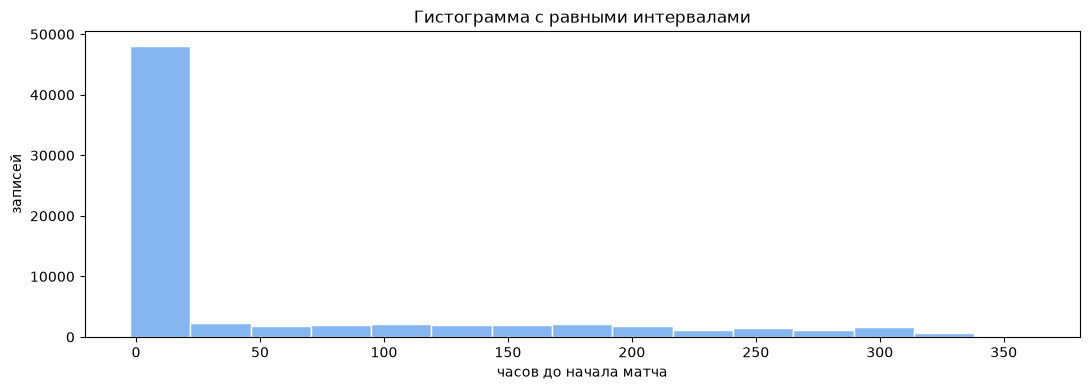

In [58]:
ax = df["hours_to_kickoff"].plot.hist(bins=15, figsize=(11, 4), color="#86b6ef", edgecolor="white")
ax.set_title("Гистограмма с равными интервалами")
ax.set_xlabel("часов до начала матча")
ax.set_ylabel("записей")
plt.tight_layout()
plt.show()

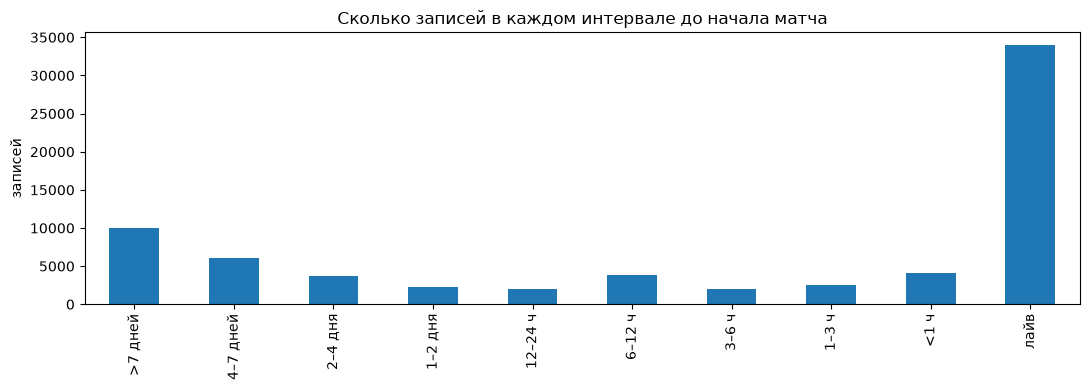

In [59]:
bins = [-3, 0, 1, 3, 6, 12, 24, 48, 96, 168, 400]
labels = ["лайв", "<1 ч", "1–3 ч", "3–6 ч", "6–12 ч", "12–24 ч", "1–2 дня", "2–4 дня", "4–7 дней", ">7 дней"]
interval = pd.cut(df["hours_to_kickoff"], bins=bins, labels=labels)

counts = interval.value_counts().reindex(labels[::-1])
ax = counts.plot.bar(figsize=(11, 4))
ax.set_title("Сколько записей в каждом интервале до начала матча")
ax.set_xlabel("")
ax.set_ylabel("записей")
ax.tick_params(axis="x")
plt.tight_layout()
plt.show()

## Шаг 11. Стадия: до матча или во время матча

In [60]:
df["stage"] = np.where(df["hours_to_kickoff"] > 0, "prematch", "live")
df["stage"].value_counts()

stage
prematch    36446
live        33956
Name: count, dtype: int64

## Шаг 12. Цена и implied_probability

Коэффициент (`price`) показывает, во сколько раз умножится ставка при выигрыше, а подразумеваемая вероятность — `implied_prob = 1 / price` - это оценка шанса исхода. Новой информации столбец не несёт, это та же цена на другой шкале.

1. Движения сравнимы между собой. Коэффициент нелинеен. Наш проект ищет резкие движения линии, поэтому мерить их удобнее в вероятностях.
2. **Видна маржа букмекера.** Сумма вероятностей по всем исходам рынка больше 1: превышение — это комиссия букмекера. 

Важно: `implied_prob` и `price` — один признак в двух масштабах, поэтому в корреляциях и моделях их нельзя считать независимыми.

In [61]:
df["price"] = df["price"].round(3)
df["implied_prob"] = (1 / df["price"]).round(5)
df[["price", "implied_prob"]].describe()

,price,implied_prob
count,70402.000000,70402.000000
mean,3.956233,0.419447
std,12.067407,0.194943
min,1.002000,0.002000
25%,1.820000,0.270270
50%,2.360000,0.423730
75%,3.700000,0.549450
max,501.000000,0.998000


In [62]:
df = df.sort_values(["fixture_id", "bookmaker", "market", "outcome", "timestamp"]).reset_index(drop=True)

## Шаг 14. Изменилась ли цена

API присылает запись не только когда меняется цена, но и когда рынок закрывают или открывают. `price_changed = True`, если цена отличается от предыдущей записи той же котировки. Первая запись котировки всегда `True`.

In [63]:
prev_price = df.groupby(["fixture_id", "bookmaker", "market", "outcome"])["price"].shift()
df["price_changed"] = prev_price.isna() | (df["price"] != prev_price)
df["price_changed"].value_counts()

price_changed
True     53487
False    16915
Name: count, dtype: int64

## Шаг 15. Порядок столбцов

In [64]:
df = df[["fixture_id", "match", "kickoff", "stage", "hours_to_kickoff", "timestamp", "bookmaker",
         "market", "outcome", "price", "implied_prob", "price_changed", "bool_isActive", "pinnacle_limit"]]
df.head()

,fixture_id,match,kickoff,stage,hours_to_kickoff,timestamp,bookmaker,market,outcome,price,implied_prob,price_changed,bool_isActive,pinnacle_limit
0,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00,prematch,309.5254,2026-08-30 16:28:28.448,bet365,1x2,away,4.750,0.21053,True,True,NaN
1,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00,prematch,306.9428,2026-08-30 19:03:25.891,bet365,1x2,away,4.333,0.23079,True,True,NaN
2,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00,prematch,305.6228,2026-08-30 20:22:37.772,bet365,1x2,away,4.333,0.23079,False,False,NaN
3,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00,prematch,305.5252,2026-08-30 20:28:29.226,bet365,1x2,away,4.333,0.23079,False,True,NaN
4,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00,prematch,302.5306,2026-08-30 23:28:10.007,bet365,1x2,away,4.333,0.23079,False,False,NaN


In [65]:
print("Размер:", df.shape)
print("Матчей:", df["fixture_id"].nunique(), "; букмекеров:", df["bookmaker"].nunique())
print("Период котировок:", df["timestamp"].min(), "—", df["timestamp"].max())
print()
print("Пропуски по столбцам:")
print(df.isna().sum())

Размер: (70402, 14)
Матчей: 16 ; букмекеров: 4
Период котировок: 2026-08-30 16:28:28.448000 — 2026-09-19 18:24:03.553000

Пропуски по столбцам:
fixture_id              0
match                   0
kickoff                 0
stage                   0
hours_to_kickoff        0
timestamp               0
bookmaker               0
market                  0
outcome                 0
price                   0
implied_prob            0
price_changed           0
bool_isActive           0
pinnacle_limit      44659
dtype: int64


In [66]:
out = df.copy()
out["kickoff"] = out["kickoff"].dt.strftime("%Y-%m-%d %H:%M:%S.%f").str[:-3]
out["timestamp"] = out["timestamp"].dt.strftime("%Y-%m-%d %H:%M:%S.%f").str[:-3]

out.to_csv("../data/transformed/epl_odds_2026-09-12_19.csv", index=False)
print("Сохранено: data/transformed/epl_odds_2026-09-12_19.csv")

Сохранено: data/transformed/epl_odds_2026-09-12_19.csv


## Часть A. Основные статистики и анализ пропущенных значений

Работаем с готовым датасетом `df` из шагов выше

План:
1. Основные статистики числовых и категориальных признаков.
2. Как распределены записи во времени (`hours_to_kickoff`).
3. Пропущенные значения: сколько, где, что означают.
4. Как обрабатываем пропуски.

### Основные статистики: `describe(include='all')`

In [67]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
fixture_id,70402,16,id1000001772221290,5499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
match,70402,16,Tottenham Hotspur — Aston Villa,5499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kickoff,70402,NaN,NaN,NaN,2026-09-15 09:03:51.129797,2026-09-12 14:00:00,2026-09-12 14:00:00,2026-09-13 13:00:00,2026-09-19 11:30:00,2026-09-19 16:30:00,NaN
stage,70402,2,prematch,36446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hours_to_kickoff,70402.0,NaN,NaN,NaN,51.770249,-2.4896,-0.6922,0.1553,78.1432,362.5248,89.495114
timestamp,70402,NaN,NaN,NaN,2026-09-13 05:17:38.233468,2026-08-30 16:28:28.448000,2026-09-12 04:02:25.398000,2026-09-12 15:55:24.638000,2026-09-18 06:13:59.060000,2026-09-19 18:24:03.553000,NaN
bookmaker,70402,4,pinnacle,25743,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market,70402,2,1x2,46602,NaN,NaN,NaN,NaN,NaN,NaN,NaN
outcome,70402,5,home,16213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,70402.0,NaN,NaN,NaN,3.956233,1.002,1.82,2.36,3.7,501.0,12.067407


**Что видим:**
- **70 402 записи** по 16 матчам АПЛ (12–19 сентября 2026), 4 букмекерам, 2 рынкам и 5 исходам. Самый «записываемый» матч — Tottenham — Aston Villa (5 499 строк).
- **Время.** Котировки собраны с 30 августа по 19 сентября: линия открывается примерно за две недели до игры.
- **`price`** — от 1.002 до 501, медиана 2.36, среднее 3.96. Среднее заметно больше медианы — признак длинного правого хвоста (подробнее ниже).
- **`price_changed`** — у 76% строк (53 487) цена отличается от предыдущей записи. Остальные 24% — записи без изменения цены, обычно это закрытие или открытие рынка.
- **`pinnacle_limit`** заполнен только в 25 743 строках, ровно столько же записей у Pinnacle. Это первый намёк на природу пропусков (раздел 2.3).

### Цена и вероятность до матча и во время матча

In [68]:
df.groupby("stage")[["price"]].describe().T.round(3)

stage             live   prematch
price count  33956.000  36446.000
      mean       5.223      2.776
      std       17.212      1.549
      min        1.002      1.010
      25%        1.869      1.800
      50%        2.700      2.163
      75%        4.100      3.600
      max      501.000     15.130

**До матча и во время матча — разные режимы рынка:**
- **До матча** цена лежит в узком диапазоне, стандартное отклонение 1.5.
- **Во время матча** максимум 501, стандартное отклонение 17. Когда исход почти решён, коэффициент на её победу улетает.

общий `describe` смешивает два режима, статистики и графики стоит смотреть отдельно по `stage`.

### Записи по интервалам и букмекерам

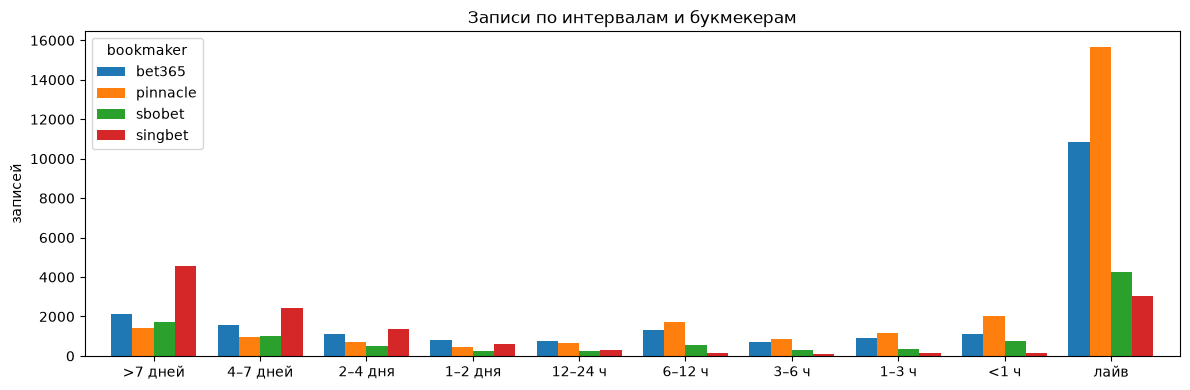

In [69]:
by_bm = pd.crosstab(interval, df["bookmaker"]).reindex(labels[::-1])
ax = by_bm.plot.bar(figsize=(12, 4), width=0.8)
ax.set_title("Записи по интервалам и букмекерам")
ax.set_xlabel("")
ax.set_ylabel("записей")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Интерпретация:**
- **bet365** даёт почти все записи раннего прематче в интервале «>7 дней». Причем цена практически не меняется. 
- **Pinnacle, Singbet и SBOBET**, наоборот, активнее всего в последние 12 часов и в лайве. Pinnacle в лайве лидирует с большим отрывом.
- **SBOBET** почти отсутствует дальше 2–4 дней: он поздно открывает линию (ниже).

### Сколько пропусков и где

In [70]:
missing = pd.DataFrame({
    "пропусков": df.isna().sum(),
    "доля, %": (df.isna().mean() * 100).round(2),
})
missing

,пропусков,"доля, %"
fixture_id,0,0.00
match,0,0.00
kickoff,0,0.00
stage,0,0.00
hours_to_kickoff,0,0.00
timestamp,0,0.00
bookmaker,0,0.00
market,0,0.00
outcome,0,0.00
price,0,0.00


In [71]:
print("Всего ячеек:", df.size)
print("Пустых ячеек:", df.isna().sum().sum())
print("Доля пустых ячеек, %:", round(df.isna().sum().sum() / df.size * 100, 2))
print("Строк хотя бы с одним пропуском, %:", round(df.isna().any(axis=1).mean() * 100, 2))

Всего ячеек: 985628
Пустых ячеек: 44659
Доля пустых ячеек, %: 4.53
Строк хотя бы с одним пропуском, %: 63.43


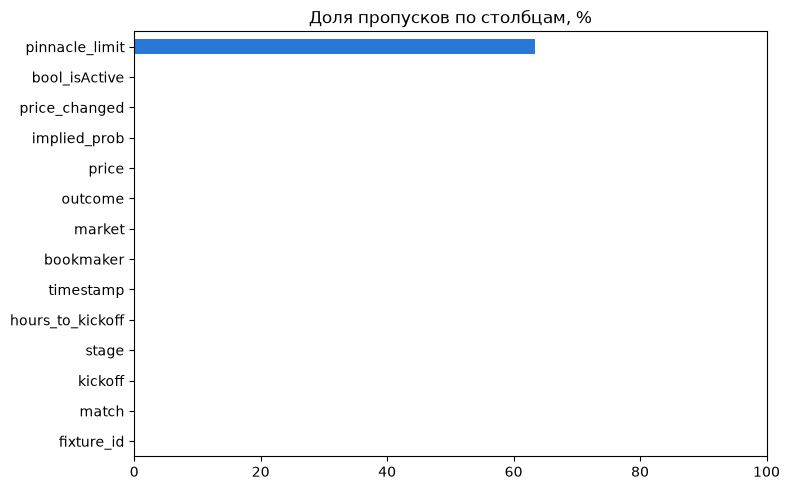

In [72]:
ax = missing["доля, %"].sort_values().plot.barh(figsize=(8, 5), color="#2a78d6")
ax.set_title("Доля пропусков по столбцам, %")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

**Итог:**
- Пропуски есть **только в одном столбце — `pinnacle_limit`:** 44 659 значений, 63.4% строк.
- В пересчёте на все ячейки датасет разрежен слабо: пустых ~4.5% ячеек. Но 63% строк содержат пропуск.
- Остальные 13 столбцов заполнены полностью.

### Обработка пропусков

**1. `pinnacle_limit` у других букмекеров — не заполняем.** Показатель у них не существует. Заполнение нулём или медианой выдумало бы лимит у bet365 и связало бы его с букмекером. Удаление строк выбросило бы 63% данных. Оставляем `NaN`: модели на деревьях работают с пропусками сами, а для других моделей признак берём только по строкам Pinnacle.

### Выводы

**Основные статистики**
- 70 402 записи, 16 матчей, 4 букмекера, рынки 1X2 и тотал 2.5, 30 августа — 19 сентября 2026. Дубликатов нет, 601 ошибочная запись bet365 с ценой 1.0 удалена.
- Датасет — это журнал изменений котировок, строка появляется, когда меняется цена или статус рынка.
- Прематч и лайв — разные режимы. До матча цены компактные, во время матча хвост до 501. `price` сильно скошен, поэтому для анализа удобнее `implied_prob`: та же информация на шкале 0–1, и движения в ней сравнимы между собой.

## Часть D. Категориальные признаки и анализ букмекерских линий

In [ ]:
categorical_cols = df.select_dtypes(
    include=["object", "bool", "string", "category"]
).columns.difference(["fixture_id", "match"]).tolist()

print("Категориальные признаки: ")
categorical_cols

Категориальный признаки: 


['bookmaker', 'bool_isActive', 'market', 'outcome', 'price_changed', 'stage']

In [74]:
df[categorical_cols].describe(include="all").T

,count,unique,top,freq
bookmaker,70402,4,pinnacle,25743
bool_isActive,70402,2,True,62267
market,70402,2,1x2,46602
outcome,70402,5,home,16213
price_changed,70402,2,True,53487
stage,70402,2,prematch,36446


In [75]:
for col in categorical_cols:
    print(f"Признак: {col}")

    stats = pd.DataFrame({
        "Количество": df[col].value_counts(dropna=False),
        "Доля (%)": (
            df[col].value_counts(
                normalize=True,
                dropna=False
            ) * 100
        ).round(2)
    })

    display(stats)

Признак: bookmaker


,Количество,Доля (%)
bookmaker,,
pinnacle,25743,36.57
bet365,21412,30.41
singbet,13209,18.76
sbobet,10038,14.26


Признак: bool_isActive


,Количество,Доля (%)
bool_isActive,,
True,62267,88.44
False,8135,11.56


Признак: market


,Количество,Доля (%)
market,,
1x2,46602,66.19
total_2.5,23800,33.81


... (2 outputs left out)

Признак: price_changed


,Количество,Доля (%)
price_changed,,
True,53487,75.97
False,16915,24.03


Признак: stage


,Количество,Доля (%)
stage,,
prematch,36446,51.77
live,33956,48.23


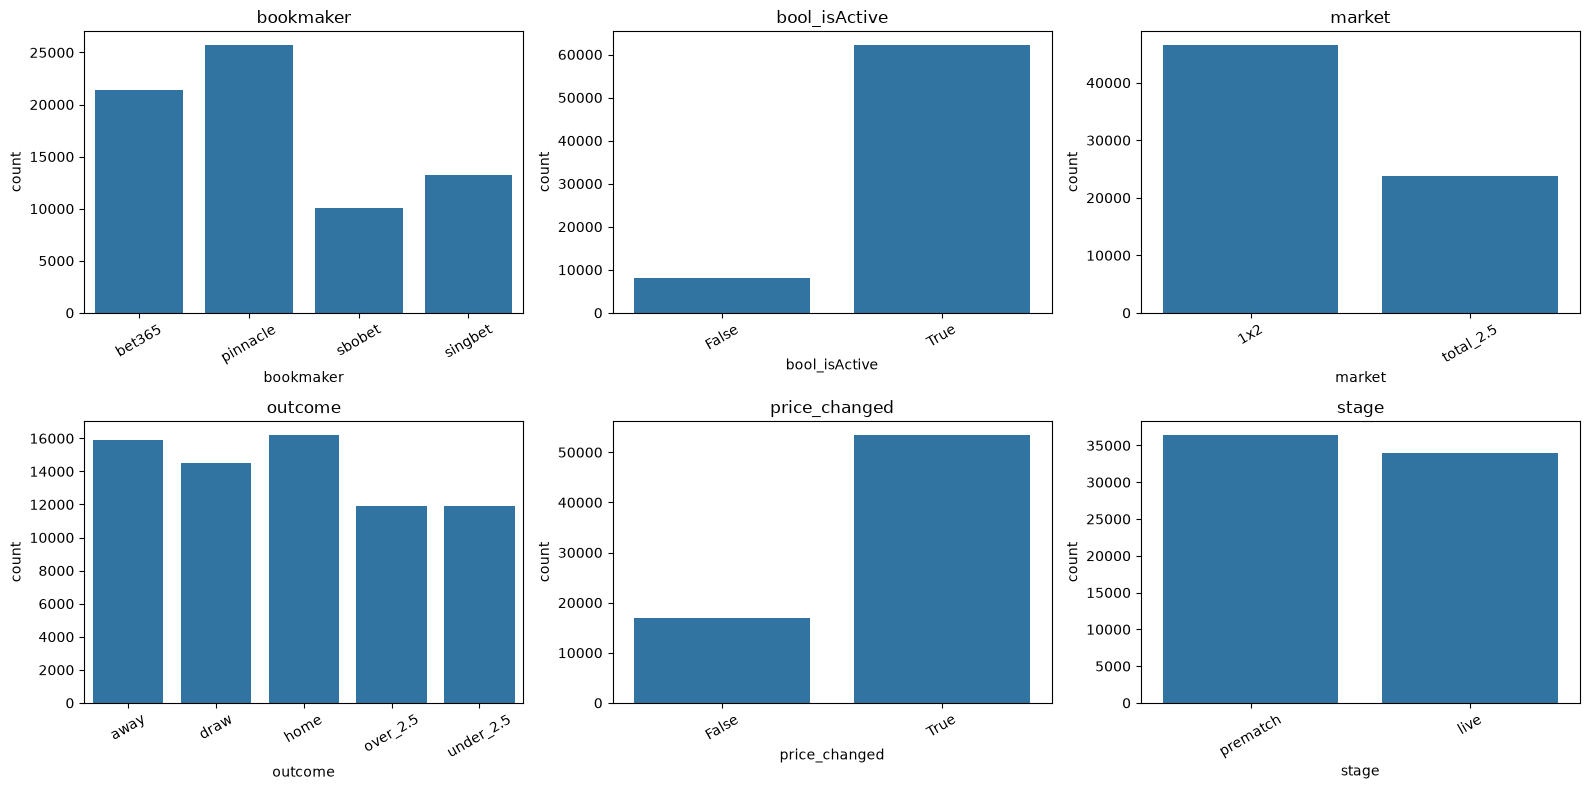

In [84]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for col, ax in zip(categorical_cols, axes.flatten()):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### Выводы по распределению категориальных признаков

В датасете есть 4 букмекера, 2 рынка и 5 типов исходов. Количество записей распределено неравномерно: на Pinnacle 36,57% наблюдений, а на SBOBET 14,26%.

Рынок 1X2 составляет 66,19% записей, а тотал 2.5 33,81%. Это различие необходимо учитывать при анализе частоты изменений: количество записей зависит также от числа исходов внутри рынка.

Предматчевые наблюдения составляют 51,77% датасета, live-наблюдения 48,23%. Так как во время матча коэффициенты могут изменяться в течение игровых событий, последующий анализ межбукмекерских движений лучше первоначально проводить отдельно на предматчевых данных.

В 11,56% записей линия неактивна. Поэтому при исследовании действующих коэффициентов нужно учитывать статус `bool_isActive`, иначе снятые котировки могут создавать ложные сигналы.

Признак `price_changed` показывает изменение относительно предыдущей записи той же котировки. При этом первая запись каждой серии обозначена как `True`, поэтому для точной оценки частоты изменений нужно исключать начальные наблюдения.

### Сравнение букмекеров

In [77]:
pre = df[df["stage"] == "prematch"].copy()

bookmaker_summary = pre.groupby("bookmaker").agg(
    observations=("price", "size"),
    matches=("fixture_id", "nunique"),
    price_change_pct=("price_changed", "mean"),
    active_pct=("bool_isActive", "mean")
)

bookmaker_summary[["price_change_pct", "active_pct"]] *= 100

display(bookmaker_summary.round(2))

,observations,matches,price_change_pct,active_pct
bookmaker,,,,
bet365,16592,16,28.07,63.55
pinnacle,10007,16,85.40,97.70
sbobet,3236,16,98.76,99.35
singbet,6611,16,72.36,88.56


#### Выводы по сравнению букмекеров

У bet365 больше всего предматчевых записей, но только 28,07% из них имеют изменение цены. При этом доля активных котировок составляет 63,55%. Это может быть из-за того, что у этого букмекера часто регистрируются снятие и повторное открытие линии без изменения самого коэффициента.

У SBOBET наоборот: 98,76% записей отмечены как изменения цены, а доля активных котировок составляет 99,35%.

Таким образом, количество записей не всегда отражает реальную частоту изменения коэффициентов. Различия могут быть как из-за поведения букмекеров, так и из-за особенностей регистрации данных в API. Поэтому при дальнейшем поиске аномалий необходимо учитывать не только изменения цены, но и статус активности линии.

market,1x2,total_2.5
bookmaker,,
bet365,8172,8420
pinnacle,6450,3557
sbobet,2769,467
singbet,4276,2335


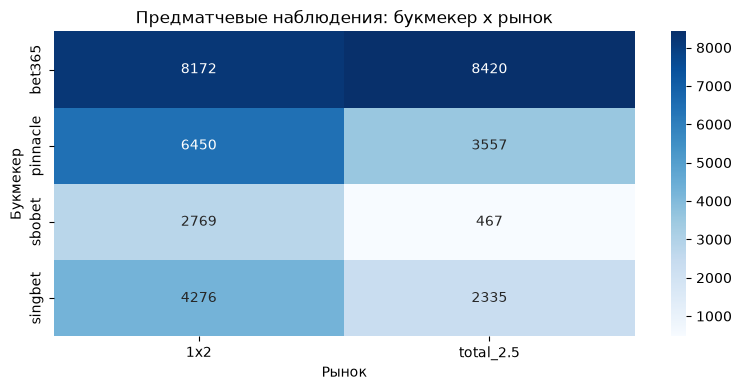

In [85]:
market_table = pd.crosstab(
    pre["bookmaker"],
    pre["market"]
)

display(market_table)

plt.figure(figsize=(8, 4))
sns.heatmap(
    market_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Предматчевые наблюдения: букмекер x рынок")
plt.xlabel("Рынок")
plt.ylabel("Букмекер")
plt.tight_layout()
plt.show()

Bet365 почти одинаково представлен в обоих рынках: 8 172 записи для 1X2 и 8 420 для тотала.

Pinnacle и Singbet имеют больше записей для 1X2.

У SBOBET особенно выраженный дисбаланс: 2 769 записей 1X2 против всего 467 для тотала.

Количество обновлений сильно различается между букмекерами и рынками - это нужно учитывать при сравнении активности линий, так как большее число записей не обязательно означает реальные частые изменения коэффициентов.

### Временная динамика букмекерских коэффициентов

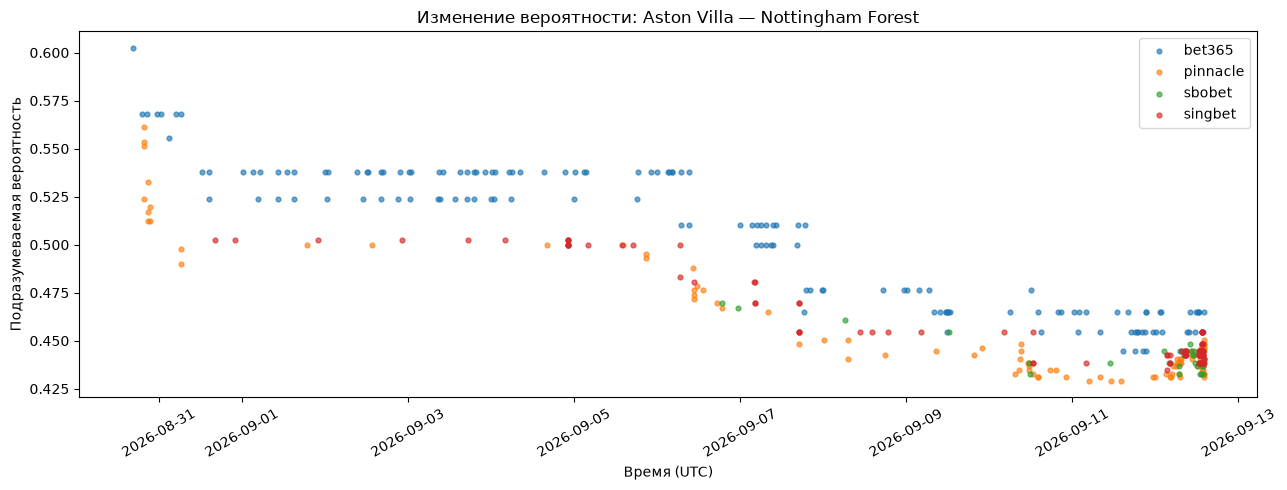

In [89]:
match_id = pre["fixture_id"].iloc[0]

sample = pre[
    (pre["fixture_id"] == match_id) &
    (pre["market"] == "1x2") &
    (pre["outcome"] == "home")
].sort_values("timestamp")

plt.figure(figsize=(13, 5))

for bookmaker, group in sample.groupby("bookmaker"):
    active = group[group["bool_isActive"]]
    plt.scatter(
        active["timestamp"],
        active["implied_prob"],
        label=bookmaker,
        s=12,
        alpha=0.65
    )

plt.title(f"Изменение вероятности: {sample['match'].iloc[0]}")
plt.xlabel("Время (UTC)")
plt.ylabel("Подразумеваемая вероятность")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### Выводы по временной динамике

На графике происходит снижение вероятности победы Aston Villa по мере приближения матча. При этом между букмекерами различия в коэффициентах и частоте зарегистрированных обновлений сохраняются.

Ближе к началу матча значения сближаются, то есть временная динамика и расхождения между букмекерами могут быть полезны для поиска аномальных движений линии.

Но для точной оценки синхронности нужно отдельно сравнить время реальных изменений коэффициентов, так как частота наблюдений у букмекеров различается.

stage,live,prematch
bookmaker,,
bet365,95.66,28.07
pinnacle,95.12,85.40
sbobet,94.72,98.76
singbet,95.20,72.36


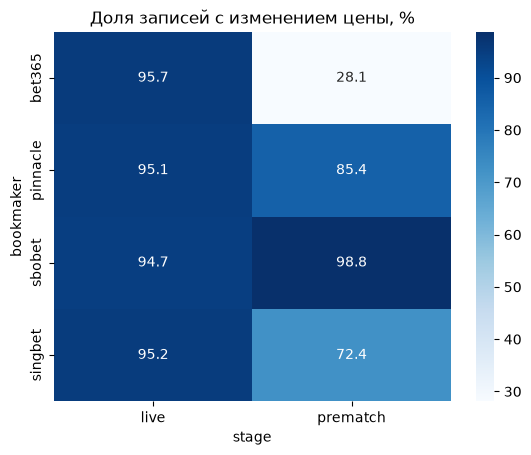

In [90]:
table = pd.crosstab(
    df["bookmaker"],
    df["stage"],
    values=df["price_changed"],
    aggfunc="mean"
) * 100

display(table.round(2))

sns.heatmap(table, annot=True, fmt=".1f", cmap="Blues")
plt.title("Доля записей с изменением цены, %")
plt.show()

#### Выводы по сравнению prematch и live

Во время матча доля изменений цены у всех букмекеров примерно 95%. При этом до начала матча происходят заметные различия: от 28,07% у bet365 до 98,76% у SBOBET.

Это может быть из-за различной активности букмекерских линий, а также регистрации обновлений. В частности, у bet365 встречается много записей со снятием и восстановлением линии без изменения коэффициента.

Таким образом, предматчевые и live-данные необходимо анализировать отдельно. При построении модели обнаружения аномалий также нужно учитывать особенности каждого букмекера, чтобы технические обновления не воспринимались как необычные движения коэффициентов.